# Connecting Python and MySQL

## Learning goals

By the end of this lesson, you should be able to:

- Create a SQLAlchemy `Engine` and connect safely to a local MySQL database.
- Execute a `SELECT` query and convert the results to a Pandas DataFrame.
- Pass values to SQL queries using parameters.
- Create a small relational database using SQL from Python.
- Populate existing relational tables from Pandas DataFrames using `to_sql()`.
- Verify inserted data with SQL `JOIN`s.

**Today's workflow:** first **MySQL → Python**, then **Python → MySQL**. We will use one connection toolkit: **SQLAlchemy + PyMySQL**.

## 1. Setup — Conda environment

We use **Conda for classroom lessons**. In your activated course environment, install the packages if they are not already available:

```bash
conda install -c conda-forge sqlalchemy pymysql pandas matplotlib ipykernel
```

Run this command **in your terminal**, not as Python code in a notebook cell. Restart the Jupyter kernel if you installed new packages. For team projects, you will use the `uv` workflow taught separately.

You need a **running MySQL 8.x server**, the `bank` database used in class, and a MySQL account with permission to create a separate practice database for the second half.

**Security:** never type your password directly into notebook source code or commit it to GitHub.

In [ ]:
import getpass

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import URL, create_engine, text

mysql_user = "root"  # Replace if your local MySQL account is different.
mysql_password = getpass.getpass("MySQL password: ")
mysql_host = "localhost"
mysql_port = 3306

## 2. Create an Engine for the `bank` database

An **Engine** knows how to connect to MySQL. It is not itself a table or a DataFrame. `URL.create()` handles credentials safely, including special characters in passwords.

In [ ]:
bank_url = URL.create(
    drivername="mysql+pymysql",
    username=mysql_user,
    password=mysql_password,
    host=mysql_host,
    port=mysql_port,
    database="bank",
)

bank_engine = create_engine(bank_url)

with bank_engine.connect() as connection:
    result = connection.execute(text("SELECT 1 AS connection_test"))
    print(result.mappings().one()["connection_test"])

## 3. Run a SQL query and retrieve its results

We will use **one consistent pattern**:

1. Write a SQL query using `text()`.
2. Open a connection with `with engine.connect()`.
3. Execute the query.
4. Retrieve the rows with `result.mappings().all()`.
5. Build a Pandas DataFrame.

`mappings()` exposes each row using its **column names**. We do not need to learn several different row-access methods today.

In [ ]:
query = text("""
    SELECT loan_id, account_id, amount, duration, status
    FROM loan
    ORDER BY loan_id
    LIMIT 10
""")

with bank_engine.connect() as connection:
    result = connection.execute(query)
    rows = result.mappings().all()

loans_df = pd.DataFrame(rows)
display(loans_df)

### Quick Check 1 — modify a query

Change the previous query to retrieve only loans with `status = 'A'`, ordered by amount from highest to lowest. Keep the `LIMIT 10` clause. Which part of the code is SQL, and which part is Python?

In [ ]:
# Your code here.

## 4. Let SQL do the aggregation

SQL is well suited to filtering, joining, and aggregating data **before** sending it to Python. Then Pandas and Matplotlib can help us explore and communicate the result.

In [ ]:
summary_query = text("""
    SELECT
        status,
        COUNT(*) AS loan_count,
        ROUND(AVG(amount), 2) AS average_amount
    FROM loan
    GROUP BY status
    ORDER BY status
""")

with bank_engine.connect() as connection:
    rows = connection.execute(summary_query).mappings().all()

loan_summary_df = pd.DataFrame(rows)
display(loan_summary_df)

ax = loan_summary_df.plot(x="status", y="loan_count", kind="bar", legend=False)
ax.set(title="Loans by status", xlabel="Loan status", ylabel="Number of loans")
plt.show()

## 5. Pass parameters safely

Avoid inserting user-provided values directly into SQL with f-strings. Use a **named parameter** such as `:minimum_amount` and pass its value separately.

In [ ]:
minimum_amount = 100_000

filtered_query = text("""
    SELECT loan_id, amount, status
    FROM loan
    WHERE amount > :minimum_amount
    ORDER BY amount DESC
    LIMIT 10
""")

with bank_engine.connect() as connection:
    rows = connection.execute(
        filtered_query,
        {"minimum_amount": minimum_amount},
    ).mappings().all()

display(pd.DataFrame(rows))

### Quick Check 2 — experiment with a parameter

Change `minimum_amount` and predict whether the result will contain more or fewer rows. Remember that `LIMIT 10` caps the number displayed.

## 6. Build a reusable SQL aggregation function

You already know `GROUP BY`, aggregate functions, Python lists, functions, and loops. Can we combine them to generate a query automatically?

Our helper receives:

- `group_columns`: one or more columns used in `GROUP BY`;
- `aggregate_columns`: numeric columns to summarize;
- `aggregate_functions`: aggregate functions to apply.

**Every selected function is applied to every selected aggregate column** (a Cartesian product). For example, two columns and two functions generate four calculations.

**Important distinction:** SQL parameters such as `:minimum_amount` are for **values**, not column names or SQL function names. To build SQL dynamically, we must validate the identifiers and functions against explicit allowlists. We will only query the `loan` table in this exercise.

In [ ]:
# Step 1: validate the inputs before constructing SQL.
# Restrict this teaching example to known columns in bank.loan.
ALLOWED_GROUP_COLUMNS = {"status", "duration", "account_id"}
ALLOWED_AGGREGATE_COLUMNS = {"amount", "payments", "duration"}
ALLOWED_FUNCTIONS = {"SUM", "AVG", "MIN", "MAX", "COUNT"}


def validate_aggregation(group_columns, aggregate_columns, aggregate_functions):
    """Check that all requested SQL identifiers and functions are allowed."""
    if not group_columns or not aggregate_columns or not aggregate_functions:
        raise ValueError("All three lists must contain at least one item.")

    if not set(group_columns) <= ALLOWED_GROUP_COLUMNS:
        raise ValueError("Unsupported GROUP BY column.")
    if not set(aggregate_columns) <= ALLOWED_AGGREGATE_COLUMNS:
        raise ValueError("Unsupported aggregate column.")

    functions = [function.upper() for function in aggregate_functions]
    if not set(functions) <= ALLOWED_FUNCTIONS:
        raise ValueError("Unsupported aggregate function.")

    return functions

### Step 2 — Construct and execute the query

We use two nested loops: one over the aggregate columns and one over the functions. Each pair becomes an expression such as `AVG(amount) AS avg_amount`.

Notice the separation of responsibilities: the function **builds the SQL**, MySQL **performs the aggregation**, and Pandas **stores the returned result**. The helper prints the generated query so you can inspect it before interpreting the output.

In [ ]:
def aggregate_loans(engine, group_columns, aggregate_columns, aggregate_functions):
    """Aggregate columns from bank.loan and return a Pandas DataFrame.

    Every aggregate function is applied to every aggregate column.
    """
    functions = validate_aggregation(
        group_columns, aggregate_columns, aggregate_functions
    )

    # Column names and function names are safe to interpolate only
    # because they were checked against the allowlists above.
    expressions = []
    for column in aggregate_columns:
        for function in functions:
            expressions.append(
                f"{function}({column}) AS {function.lower()}_{column}"
            )

    selected_columns = group_columns + expressions
    query_sql = (
        "SELECT " + ", ".join(selected_columns)
        + " FROM loan"
        + " GROUP BY " + ", ".join(group_columns)
        + " ORDER BY " + ", ".join(group_columns)
    )

    print("Generated SQL:\n", query_sql)

    with engine.connect() as connection:
        rows = connection.execute(text(query_sql)).mappings().all()

    return pd.DataFrame(rows)

In [ ]:
# Two columns x two functions = four aggregate expressions.
aggregation_df = aggregate_loans(
    engine=bank_engine,
    group_columns=["status", "duration"],
    aggregate_columns=["amount", "payments"],
    aggregate_functions=["SUM", "AVG"],
)

display(aggregation_df)

### Quick Check 3 — Explore the query generator

1. Predict how many aggregate expressions are generated with **three columns** and **two functions**.
2. Change `group_columns` to `["status"]` and compare the number of result rows.
3. Add `"MAX"` to `aggregate_functions`. Which new output columns appear?
4. Try an invalid column name. Why does the function reject it instead of sending the query to MySQL?

**Note:** This function is intentionally limited to a known table and selected columns. A production-ready query builder would need more extensive identifier handling, type validation, and testing.

---

# Part 2 — Build and populate a coffee shop database

Next week's project asks you to design and populate a relational database from a dataset. Let's practice that complete workflow with **small fictional data**.

We will create a **separate practice database** called `coffee_shop_demo`. We will **not modify the `bank` database**.

> **Important:** This notebook resets the four demo tables when rerun. Use it only with the dedicated `coffee_shop_demo` database, never with a database containing important data.

## 7. Design the relational model

A customer can place many orders. An order can contain many products, and a product can appear in many orders. Therefore, the relationship between `orders` and `products` is **many-to-many (N:N)**.

We resolve that relationship with a **bridge table**, `order_items`, using a dedicated primary key (`order_item_id`) and two foreign keys. For this simplified business model, a product appears at most once per order; its `quantity` records how many units were purchased.

`unit_price` records the price **at the time of purchase**, even if the product's catalog price changes later.

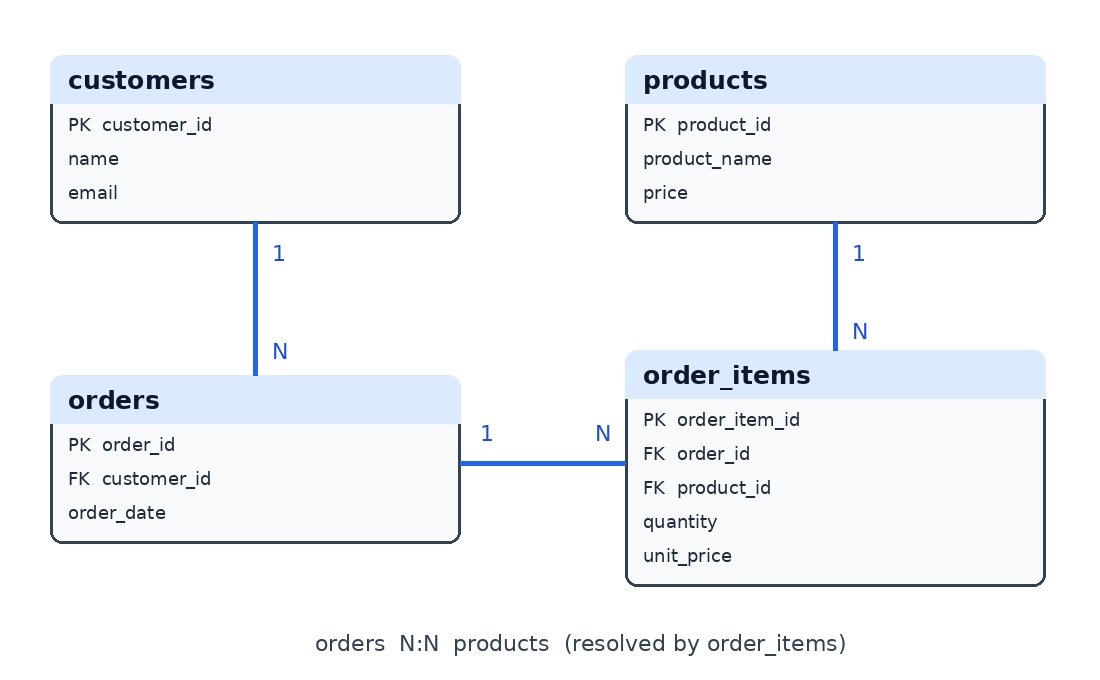

**ERD:** `customers` 1:N `orders`; `orders` 1:N `order_items`; `products` 1:N `order_items`.

## 8. Create a separate database

We connect to MySQL **without selecting a database**, create `coffee_shop_demo`, and then create a second Engine pointing to it. Creating databases requires suitable permissions.

In [ ]:
server_url = URL.create(
    drivername="mysql+pymysql",
    username=mysql_user,
    password=mysql_password,
    host=mysql_host,
    port=mysql_port,
)
server_engine = create_engine(server_url)

with server_engine.begin() as connection:
    connection.execute(text("CREATE DATABASE IF NOT EXISTS coffee_shop_demo"))

coffee_url = URL.create(
    drivername="mysql+pymysql",
    username=mysql_user,
    password=mysql_password,
    host=mysql_host,
    port=mysql_port,
    database="coffee_shop_demo",
)
coffee_engine = create_engine(coffee_url)
print("Practice database ready.")

## 9. Create four tables with SQL

We define the database structure using **SQL**, not Pandas. This lets us specify primary keys, foreign keys, data types, and constraints explicitly.

**Demo reset:** we drop only the four tables inside `coffee_shop_demo` so the notebook can be rerun without duplicate rows. We drop child tables before parent tables because of foreign-key dependencies.

For clarity, we use fixed integer IDs in the example DataFrames, although the MySQL tables support `AUTO_INCREMENT`.

In [ ]:
table_statements = [
    """
    CREATE TABLE customers (
        customer_id INT AUTO_INCREMENT PRIMARY KEY,
        name VARCHAR(100) NOT NULL,
        email VARCHAR(150) NOT NULL UNIQUE
    )
    """,
    """
    CREATE TABLE products (
        product_id INT AUTO_INCREMENT PRIMARY KEY,
        product_name VARCHAR(100) NOT NULL,
        price DECIMAL(10, 2) NOT NULL
    )
    """,
    """
    CREATE TABLE orders (
        order_id INT AUTO_INCREMENT PRIMARY KEY,
        customer_id INT NOT NULL,
        order_date DATE NOT NULL,
        FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
    )
    """,
    """
    CREATE TABLE order_items (
        order_item_id INT AUTO_INCREMENT PRIMARY KEY,
        order_id INT NOT NULL,
        product_id INT NOT NULL,
        quantity INT NOT NULL,
        unit_price DECIMAL(10, 2) NOT NULL,
        UNIQUE (order_id, product_id),
        FOREIGN KEY (order_id) REFERENCES orders(order_id),
        FOREIGN KEY (product_id) REFERENCES products(product_id)
    )
    """,
]

with coffee_engine.begin() as connection:
    for table_name in ["order_items", "orders", "products", "customers"]:
        connection.execute(text(f"DROP TABLE IF EXISTS {table_name}"))

    for statement in table_statements:
        connection.execute(text(statement))

print("Four relational tables created.")

### Why use `engine.begin()` here?

`engine.connect()` is enough for reading data. `engine.begin()` creates a transaction for data-changing statements and **commits successful DML automatically** (or rolls it back if an error occurs). In MySQL, many DDL operations such as `CREATE TABLE` cause implicit commits, so this block should **not** be understood as an all-or-nothing transaction for schema changes.

## 10. Prepare one DataFrame per table

This is exactly the pattern you may use in the next project: transform your source dataset into **one DataFrame for each table** in your relational design.

Our IDs are explicit to keep foreign-key relationships easy to inspect.

In [ ]:
customers_df = pd.DataFrame({
    "customer_id": [1, 2, 3, 4, 5],
    "name": ["Ana", "Bruno", "Carla", "Diego", "Elena"],
    "email": ["ana@example.com", "bruno@example.com", "carla@example.com",
              "diego@example.com", "elena@example.com"],
})

products_df = pd.DataFrame({
    "product_id": [1, 2, 3, 4],
    "product_name": ["Espresso", "Cappuccino", "Croissant", "Tea"],
    "price": [2.50, 3.50, 2.80, 2.20],
})

orders_df = pd.DataFrame({
    "order_id": [101, 102, 103, 104, 105],
    "customer_id": [1, 2, 1, 3, 5],
    "order_date": pd.to_datetime([
        "2026-10-01", "2026-10-01", "2026-10-02", "2026-10-02", "2026-10-03"
    ]).date,
})

order_items_df = pd.DataFrame({
    "order_item_id": [1, 2, 3, 4, 5, 6, 7, 8, 9],
    "order_id": [101, 101, 102, 102, 103, 103, 104, 105, 105],
    "product_id": [1, 3, 2, 4, 1, 2, 3, 2, 4],
    "quantity": [2, 1, 1, 1, 1, 2, 3, 1, 2],
    "unit_price": [2.50, 2.80, 3.50, 2.20, 2.50, 3.50, 2.80, 3.50, 2.20],
})

for name, frame in [
    ("customers", customers_df),
    ("products", products_df),
    ("orders", orders_df),
    ("order_items", order_items_df),
]:
    print(f"{name}: {len(frame)} rows")
    display(frame.head())

## 11. Insert the DataFrames into existing MySQL tables

`DataFrame.to_sql()` writes rows to SQL tables. We choose:

- `if_exists="append"`: insert into an **existing** table without replacing its structure.
- `index=False`: do not write the Pandas index as a database column.
- `chunksize=1000`: send rows in batches, which can help with larger datasets.

**Important:** `to_sql()` is not a relational database designer. We created the tables first so their primary keys, foreign keys, and constraints already exist.

Insert **parent tables first**, then tables that reference them. We use a single transaction for these inserts.

In [ ]:
with coffee_engine.begin() as connection:
    customers_df.to_sql(
        "customers", con=connection, if_exists="append", index=False, chunksize=1000
    )
    products_df.to_sql(
        "products", con=connection, if_exists="append", index=False, chunksize=1000
    )
    orders_df.to_sql(
        "orders", con=connection, if_exists="append", index=False, chunksize=1000
    )
    order_items_df.to_sql(
        "order_items", con=connection, if_exists="append", index=False, chunksize=1000
    )

print("All four tables populated.")

### Quick Check 4 — insertion order

Why do we insert `customers` before `orders`, and `orders` before `order_items`? What could happen if we tried to insert an `order_item` referencing an order that does not exist?

**Think first:** MySQL foreign-key constraints protect the consistency of the data.

Use the ERD to trace the dependencies. `customers` and `products` can be inserted in either order; `orders` depends on `customers`, and `order_items` depends on both `orders` and `products`. **The order follows foreign keys, not a fixed rule about bridge tables.**

## 12. Verify the data with a JOIN

Now return to the **MySQL → Python** workflow. The database stores related tables; a `JOIN` reconstructs the information needed for an analysis.

In [ ]:
sales_query = text("""
    SELECT
        c.name AS customer,
        o.order_id,
        o.order_date,
        p.product_name,
        oi.quantity,
        oi.unit_price,
        ROUND(oi.quantity * oi.unit_price, 2) AS line_total
    FROM customers AS c
    JOIN orders AS o ON o.customer_id = c.customer_id
    JOIN order_items AS oi ON oi.order_id = o.order_id
    JOIN products AS p ON p.product_id = oi.product_id
    ORDER BY o.order_id, oi.order_item_id
""")

with coffee_engine.connect() as connection:
    sales_rows = connection.execute(sales_query).mappings().all()

sales_df = pd.DataFrame(sales_rows)
display(sales_df)
print("Order lines returned:", len(sales_df))

## 13. Answer a business question

**Question:** Which products generated the most revenue?

We could calculate this in Pandas, but we already know how to use `JOIN`, `GROUP BY`, and `SUM` in SQL. Let MySQL perform the aggregation, then visualize the result in Python.

In [ ]:
revenue_query = text("""
    SELECT
        p.product_name,
        ROUND(SUM(oi.quantity * oi.unit_price), 2) AS revenue
    FROM order_items AS oi
    JOIN products AS p ON p.product_id = oi.product_id
    GROUP BY p.product_id, p.product_name
    ORDER BY revenue DESC
""")

with coffee_engine.connect() as connection:
    revenue_rows = connection.execute(revenue_query).mappings().all()

revenue_df = pd.DataFrame(revenue_rows)
display(revenue_df)

ax = revenue_df.plot(x="product_name", y="revenue", kind="bar", legend=False)
ax.set(title="Coffee shop revenue by product", xlabel="Product", ylabel="Revenue")
plt.show()

### Quick Check 5 — a small extension

1. Write a SQL query to calculate the **total amount spent by each customer**.
2. Include customers with **no orders** (hint: `LEFT JOIN`).
3. Load the result into a DataFrame and check whether Elena, Ana, and the other customers appear as expected.

Start with the SQL query; only then connect it to Python.

In [ ]:
# Your code here.

## Mini challenge — prepare for the database project

Imagine the café introduces a new product, **Hot Chocolate** (`product_id = 5`, price `3.20`).

- Create a one-row DataFrame with the same columns as `products_df`.
- Insert it into the **existing** `products` table using `to_sql()`.
- Query MySQL to verify that it was inserted.

**Note:** this challenge inserts a new row and is not designed to be rerun unchanged; a second insertion with the same `product_id` will violate the primary key. Use a new ID or reset the demo tables before repeating it.

In [ ]:
# Your code here.

## TAKEAWAYS

- An SQLAlchemy **Engine** stores the configuration needed to connect to a database.
- `with engine.connect()` is a clear way to run read-only queries and release connections.
- `text()` plus named parameters lets us pass **values** safely from Python.
- Dynamic SQL column names and functions must be validated; our aggregation helper uses allowlists and nested loops.
- `result.mappings().all()` → `pd.DataFrame(...)` is our **single standard pattern** for retrieving query results.
- `engine.begin()` is useful for transactional **data changes**.
- Design relational tables in **SQL**, including their primary keys, foreign keys, and constraints.
- Prepare **one DataFrame per table**, then use `to_sql(if_exists="append", index=False)` to populate those existing tables.
- Insert related tables in **foreign-key dependency order**.
- SQL and Python complement one another: **SQL stores, joins, filters, and aggregates; Pandas and Matplotlib analyze and visualize**.

**EXTRA practice:** the Sakila lab asks you to retrieve rental data for selected months and compare customer activity. You can apply the same SQLAlchemy → DataFrame pattern from Part 1.